
# Data Scaling in Neural Networks | Feature Scaling in ANN

## 1. Introduction

**Data Scaling** is a preprocessing technique used to bring numerical features of a dataset into a similar range. It prevents features with larger numerical values from dominating those with smaller values during neural network training.

For example, consider a dataset containing:

- Age: 18–60
- Salary: 20,000–150,000
- Experience: 1–20 years

Since salary has much larger numerical values than age and experience, it may have a greater influence on the learning process if the features are not scaled.

Therefore, feature scaling helps neural networks learn more efficiently and achieve better performance.

## 2. Why Is Feature Scaling Important in ANN?

Feature scaling is important for the following reasons:

1. **Faster Convergence:** It helps gradient descent converge faster by making the optimization process more stable.

2. **Prevents Feature Dominance:** It prevents features with larger numerical ranges from dominating the learning process.

3. **Improves Training Stability:** It reduces large differences in feature values, making weight updates more manageable.

4. **Better Gradient Descent Performance:** It helps the optimization algorithm move toward the minimum more efficiently.

5. **Improves Numerical Stability:** It reduces the possibility of extremely large values during calculations.

## 3. Common Feature Scaling Techniques

There are two commonly used techniques for scaling numerical features in neural networks.

### A. Standardization (Z-Score Normalization)

Standardization transforms data so that it has a mean of approximately 0 and a standard deviation of 1.

**Formula:**

$$
Z = \frac{X-\mu}{\sigma}
$$

Where:

- $X$ = Original feature value
- $\mu$ = Mean of the feature
- $\sigma$ = Standard deviation of the feature
- $Z$ = Scaled value

**Example:**

If a feature has a mean of 50 and a standard deviation of 10, and the original value is 70:

$$
Z = \frac{70-50}{10}=2
$$

The scaled value becomes 2.

**Advantages:**
- Useful when features have different distributions and ranges.
- Commonly used with neural networks.
- Less affected by extreme values than Min-Max scaling, although outliers can still influence the mean and standard deviation.

### B. Min-Max Scaling (Normalization)

Min-Max Scaling transforms feature values into a fixed range, usually between 0 and 1.

**Formula:**

$$
X_{\text{scaled}} =
\frac{X-X_{\min}}{X_{\max}-X_{\min}}
$$

Where:

- $X$ = Original value
- $X_{\min}$ = Minimum value
- $X_{\max}$ = Maximum value

**Example:**

If the minimum value is 10, the maximum value is 100, and the original value is 50:

$$
X_{\text{scaled}} = \frac{50-10}{100-10}
$$

$$
X_{\text{scaled}} = \frac{40}{90} \approx 0.44
$$

The scaled value becomes approximately 0.44.

**Advantages:**
- Converts values into a fixed range.
- Useful when a bounded input range is preferred.
- Can work well with activation functions such as Sigmoid and Tanh.

**Disadvantage:** It is sensitive to outliers because extreme values affect the minimum and maximum.

## 4. Difference Between Standardization and Normalization

| Standardization | Min-Max Normalization |
|---|---|
| Uses mean and standard deviation. | Uses minimum and maximum values. |
| Mean becomes approximately 0. | Values usually range from 0 to 1. |
| Does not have a fixed output range. | Produces a fixed output range. |
| Less sensitive to outliers than Min-Max scaling. | Highly sensitive to outliers. |
| Commonly used in neural networks. | Useful when a fixed input range is required. |

## 5. Important Points to Remember

- Feature scaling is generally recommended when training neural networks with numerical input features.
- Scaling helps gradient-based optimizers such as SGD and Adam learn more efficiently.
- Always fit the scaler using the training dataset only.
- Apply the same fitted scaler to both training and testing data to prevent data leakage.
- Do not scale the target variable unless the problem and model design require it.
- Scaling is not always necessary for every type of machine learning algorithm.

## Conclusion

Data scaling is an important preprocessing step in neural networks. It brings features into comparable numerical ranges, improves gradient descent convergence, and makes training more stable. Standardization and Min-Max Normalization are two commonly used feature scaling techniques.


# Code Demo

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

In [9]:
!pip install kagglehub -q
import kagglehub
import shutil
import os
import pandas as pd

# Download the latest version of the Social Network Ads dataset
path = kagglehub.dataset_download("rakeshrau/social-network-ads")

# Find the CSV file inside the downloaded path
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
src_path = os.path.join(path, csv_file)
dest_path = '/content/Social_Network_Ads.csv'

# Copy it to our workspace
shutil.copy(src_path, dest_path)

# Load and view the dataset
df = pd.read_csv(dest_path)
display(df.head())

100%|██████████| 3.27k/3.27k [00:00<00:00, 2.13MB/s]

Extracting files...


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [10]:
df = df.iloc[:,2:]
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


<Axes: xlabel='Age', ylabel='EstimatedSalary'>

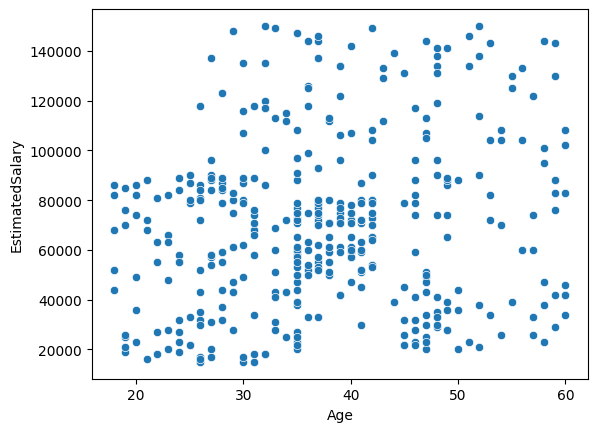

In [15]:
sns.scatterplot(x=df.iloc[:,0], y=df.iloc[:,1])

In [16]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [17]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [18]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [19]:
model = Sequential()

model.add(Dense(128,activation = 'relu',input_dim = 2))
model.add(Dense(1,activation = 'sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(loss = 'binary_crossentropy',optimizer = 'adam', metrics = ['accuracy'])

In [22]:
history = model.fit(X_train,y_train,validation_data = (X_test,y_test),epochs = 100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.3469 - loss: 5124.4072 - val_accuracy: 0.4000 - val_loss: 1734.7328
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4969 - loss: 1073.2297 - val_accuracy: 0.6000 - val_loss: 1636.9667
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6531 - loss: 983.3885 - val_accuracy: 0.4000 - val_loss: 78.5542
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4281 - loss: 275.6386 - val_accuracy: 0.6000 - val_loss: 415.6500
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5406 - loss: 321.0370 - val_accuracy: 0.4000 - val_loss: 198.0910
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4844 - loss: 108.6765 - val_accuracy: 0.6000 - val_loss: 3.5076
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5437 - loss: 15.5220 - val_accuracy: 0.4000 - val_loss: 10.1987
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5656 - loss: 26.40

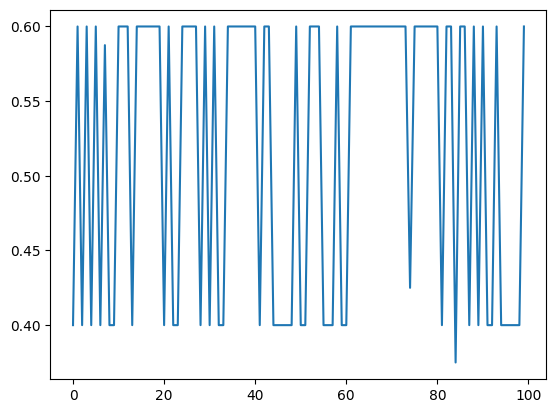

In [23]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

# Applying Scaling

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [27]:
X_train_scaled

array([[ 0.88928823, -0.65924556],
       [-0.17254846,  0.87392651],
       [-1.04132394, -0.36440478],
       [ 0.98581884,  0.6085698 ],
       [-0.94479333,  0.57908572],
       [ 0.40663519,  0.01888824],
       [ 0.98581884,  2.11225779],
       [ 0.31010458, -0.30543662],
       [ 1.7580637 , -0.27595254],
       [-0.17254846,  2.20071003],
       [ 1.7580637 ,  1.0213469 ],
       [-1.33091576, -1.48479975],
       [ 2.04765553,  0.54960165],
       [ 1.27541066,  1.90586924],
       [-1.13785454,  0.31372902],
       [-0.36560968, -0.77718187],
       [-1.71703819,  0.49063349],
       [-0.5586709 , -1.51428383],
       [ 0.31010458, -0.71821372],
       [ 0.02051275, -0.57079333],
       [ 0.02051275,  0.04837232],
       [-0.07601785, -0.51182517],
       [-0.6552015 , -1.51428383],
       [ 0.02051275,  0.31372902],
       [ 0.31010458,  0.07785639],
       [-0.46214029, -1.13099081],
       [-0.75173211, -1.54376791],
       [-0.26907907, -0.65924556],
       [-1.13785454,

<Axes: >

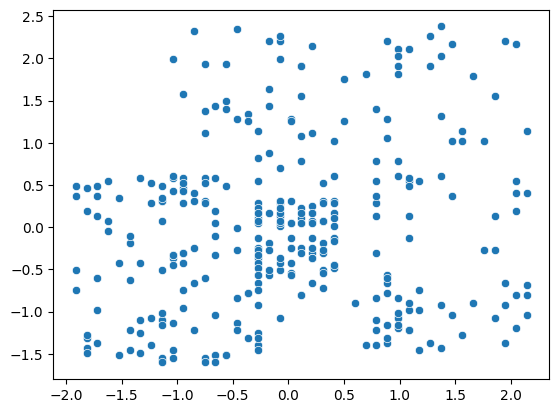

In [28]:
sns.scatterplot(x=X_train_scaled[:,0], y=X_train_scaled[:,1])

In [29]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history = model.fit(X_train_scaled,y_train,validation_data=(X_test_scaled,y_test),epochs=100)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8219 - loss: 0.6235 - val_accuracy: 0.8625 - val_loss: 0.5890
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8375 - loss: 0.5720 - val_accuracy: 0.8125 - val_loss: 0.5390
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8531 - loss: 0.5286 - val_accuracy: 0.8125 - val_loss: 0.4972
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8562 - loss: 0.4919 - val_accuracy: 0.8125 - val_loss: 0.4628
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8594 - loss: 0.4606 - val_accuracy: 0.8125 - val_loss: 0.4337
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8594 - loss: 0.4336 - val_accuracy: 0.8125 - val_loss: 0.4095
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8562 - loss: 0.4099 - val_accuracy: 0.8250 - val_loss: 0.3901
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8562 - loss: 0.3905 - val_accuracy: 0.8250 -

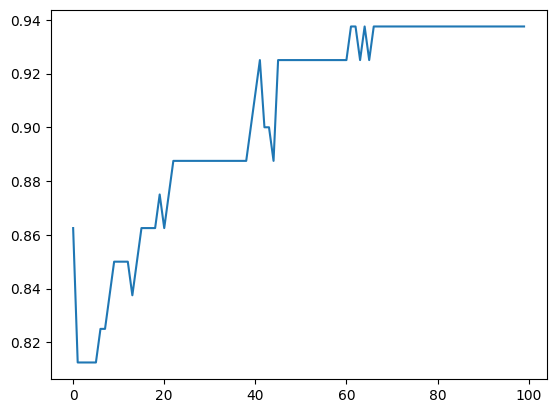

In [30]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])